# 06 — Extra Experiments (CV only — the test set is NOT used here)
Checks that back up the decisions of notebooks 02–05:
1. **Imbalance:** sample weights and oversampling of surged rides, applied inside the training folds only.
2. **Outliers:** winsorizing inside the Pipeline (1/99 and 5/95 percentiles) vs. no clipping.
3. **Why the final model:** statistical tie analysis of the top tuned models.
4. **Bonus B1:** classic tree models vs. their newer gradient-boosting versions.
5. **Weak result:** learning curve and feature importance.
6. **Missing values:** the Pipeline's imputers at work.
7. **30k sample:** CV on the sample vs. CV on the full training set vs. the stored test result.

All runs use the same `TimeSeriesSplit(5)` and, unless stated otherwise, the same 30k training sample as notebooks 04/05.

In [1]:
# --- Project setup (works locally and on Colab after cloning the repo) ---
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: /tmp/fix


In [2]:
import json, time, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, learning_curve

from src.preprocessing import make_preprocessor
from src.modeling import load_split, cv_sample, make_cv, SCORING
from src.model_zoo import MODELS
from src.imbalance import cv_balance_eval, apply_strategy
from src.outliers import iqr_report
from src.features import NUMERIC_FEATURES

warnings.filterwarnings("ignore")
X_train, X_test, y_train, y_test = load_split()      # X_test / y_test are NOT used in this notebook
del X_test, y_test
X_cv, y_cv = cv_sample(X_train, y_train)
cv = make_cv()

tuning = pd.read_csv("reports/tuning_comparison.csv")
final_metrics = json.load(open("reports/final_metrics.json"))
FINAL = final_metrics["model"]
print("Final model from notebook 05:", FINAL)

def tuned_pipeline(name, X=X_cv, winsorize=None):
    params = json.loads(tuning.set_index("Model").loc[name, "Best Parameters"])
    est = clone(MODELS[name][2]).set_params(**params)
    return Pipeline([("preprocessor", make_preprocessor(X, winsorize=winsorize)), ("model", est)])

def summarize(df, by):
    g = df.groupby(by, sort=False)
    out = g[["RMSE", "RMSE surged only", "R2", "Mean pred (non-surged)", "Mean pred (surged)"]].mean()
    out.insert(1, "RMSE std", g["RMSE"].std(ddof=0))   # same convention as GridSearchCV
    out["train surged share"] = g["train_surged_share"].mean()
    return out

Final model from notebook 05: Random Forest


## 1. Imbalance — sample weights and oversampling (train folds only)
About 93% of rides have surge = 1.0. SMOTE is for classes, so for a continuous target we test:
- **sample_weight**: surged rides count ×3 or ×10 in the loss,
- **random oversampling**: duplicate surged rides until they are 15% or 30% of the training rows.

Inside each `TimeSeriesSplit` fold, the strategy changes **only the training part**. The validation part keeps the real
distribution, so the scores are honest. Models: the tuned final model and tuned Lasso (a linear reference).

In [3]:
strategies = {
    "none": ("none",),
    "weight x3": ("weight", 3),
    "weight x10": ("weight", 10),
    "oversample to 15%": ("oversample", 0.15),
    "oversample to 30%": ("oversample", 0.30),
}
rows = []
for model_name in [FINAL, "Lasso"]:
    for s_name, strat in strategies.items():
        t0 = time.time()
        res = cv_balance_eval(tuned_pipeline(model_name), X_cv, y_cv, cv, strat)
        res["Model"], res["Strategy"] = model_name, s_name
        rows.append(res)
        print(f"{model_name:15s} {s_name:18s} RMSE={res['RMSE'].mean():.5f}  surged-only={res['RMSE surged only'].mean():.4f}  ({time.time()-t0:.0f}s)")
imb = pd.concat(rows)
imb_summary = summarize(imb, ["Model", "Strategy"])
display(imb_summary.round(5))
imb_summary.round(6).to_csv("reports/imbalance_experiment.csv")

Random Forest   none               RMSE=0.13168  surged-only=0.4839  (30s)


Random Forest   weight x3          RMSE=0.14482  surged-only=0.4279  (31s)


Random Forest   weight x10         RMSE=0.20791  surged-only=0.3437  (28s)


Random Forest   oversample to 15%  RMSE=0.13917  surged-only=0.4416  (41s)


Random Forest   oversample to 30%  RMSE=0.17212  surged-only=0.3811  (40s)


Lasso           none               RMSE=0.13212  surged-only=0.4898  (1s)


Lasso           weight x3          RMSE=0.14728  surged-only=0.4275  (1s)


Lasso           weight x10         RMSE=0.22055  surged-only=0.3460  (1s)


Lasso           oversample to 15%  RMSE=0.13943  surged-only=0.4447  (1s)


Lasso           oversample to 30%  RMSE=0.17251  surged-only=0.3857  (2s)


RMSE  RMSE std  RMSE surged only       R2  \
Model         Strategy                                                          
Random Forest none               0.13168   0.00659           0.48391  0.02908   
              weight x3          0.14482   0.00611           0.42791 -0.17617   
              weight x10         0.20791   0.00573           0.34367 -1.42900   
              oversample to 15%  0.13917   0.00539           0.44160 -0.08581   
              oversample to 30%  0.17212   0.00562           0.38110 -0.66594   
Lasso         none               0.13212   0.00652           0.48982  0.02261   
              weight x3          0.14728   0.01342           0.42750 -0.21395   
              weight x10         0.22055   0.03901           0.34600 -1.75624   
              oversample to 15%  0.13943   0.00814           0.44470 -0.08854   
              oversample to 30%  0.17251   0.01261           0.38573 -0.67088   

                                 Mean pred (non-surged)  Mean pred (surged)  \
Model         Strategy                                                        
Random Forest none                              1.03096             1.04871   
              weight x3                         1.07652             1.11773   
              weight x10                        1.16128             1.23764   
              oversample to 15%                 1.06371             1.10000   
              oversample to 30%                 1.11600             1.18008   
Lasso         none                              1.03179             1.04219   
              weight x3                         1.08242             1.11775   
              weight x10                        1.16552             1.24270   
              oversample to 15%                 1.06715             1.09580   
              oversample to 30%                 1.11628             1.17290   

                                 train surged share  
Model         Strategy                               
Random Forest none                          0.06791  
              weight x3                     0.06791  
              weight x10                    0.06791  
              oversample to 15%             0.15003  
              oversample to 30%             0.30002  
Lasso         none                          0.06791  
              weight x3                     0.06791  
              weight x10                    0.06791  
              oversample to 15%             0.15003  
              oversample to 30%             0.30002

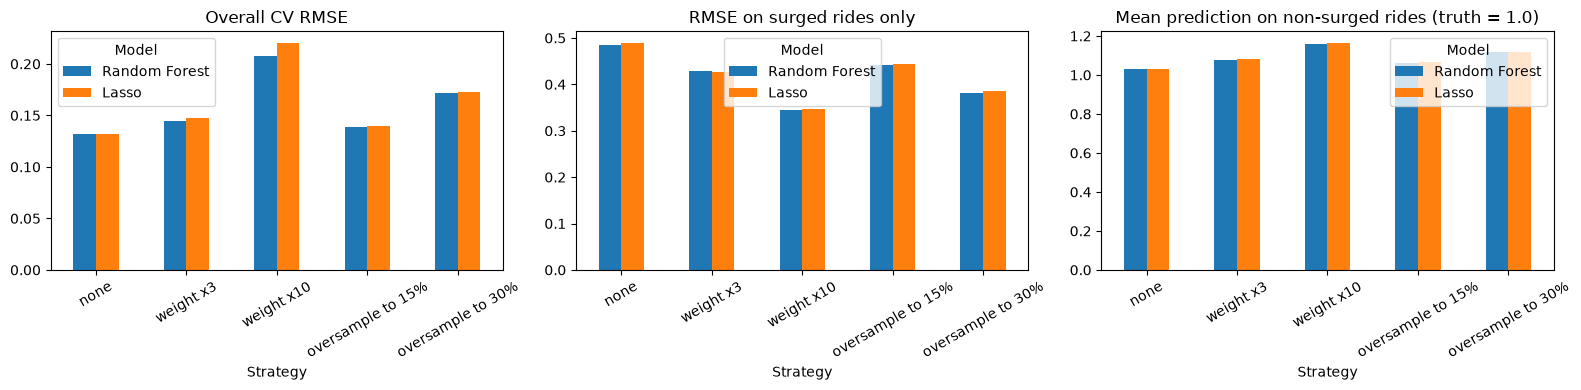

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ["RMSE", "RMSE surged only", "Mean pred (non-surged)"],
                          ["Overall CV RMSE", "RMSE on surged rides only", "Mean prediction on non-surged rides (truth = 1.0)"]):
    imb_summary[col].unstack(0).plot.bar(ax=ax); ax.set_title(title); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("reports/figures/06_imbalance.png", dpi=100); plt.show()

**Decision.** The final model is trained **without** balancing, because the project metric is RMSE over all rides and
the test set keeps the real ~7% surge rate. A balanced model is kept as a ready alternative (below).
The trade-off it makes is read from the table above.

In [5]:
fm = imb_summary.loc[FINAL]
# Ready alternative = lowest surged-only RMSE among strategies whose overall RMSE is at most 10% worse than "none"
acceptable = fm[(fm.index != "none") & (fm["RMSE"] <= fm.loc["none", "RMSE"] * 1.10)]
alt_name = acceptable["RMSE surged only"].idxmin()
print("Acceptable strategies (overall RMSE within +10%):", acceptable.index.tolist())
print("Chosen balanced alternative for", FINAL, "->", alt_name)
display(fm.loc[["none", alt_name]].round(5))

# Ready alternative: same tuned model, trained on the FULL training set with that strategy (no test evaluation here).
Xb, yb, fit_params = apply_strategy(X_train, y_train, strategies[alt_name])
alt_model = tuned_pipeline(FINAL, X=X_train)
alt_model.fit(Xb, yb, **fit_params)
joblib.dump(alt_model, "models/alt_balanced_model.joblib")
json.dump({"model": FINAL, "strategy": alt_name}, open("models/alt_balanced_model.json", "w"))
print("Saved models/alt_balanced_model.joblib  (same 14 input columns, drop-in for app.py)")

Acceptable strategies (overall RMSE within +10%): ['weight x3', 'oversample to 15%']
Chosen balanced alternative for Random Forest -> weight x3


,RMSE,RMSE std,RMSE surged only,R2,Mean pred (non-surged),Mean pred (surged),train surged share
Strategy,,,,,,,
none,0.13168,0.00659,0.48391,0.02908,1.03096,1.04871,0.06791
weight x3,0.14482,0.00611,0.42791,-0.17617,1.07652,1.11773,0.06791


Saved models/alt_balanced_model.joblib  (same 14 input columns, drop-in for app.py)


## 2. Outliers — winsorizing inside the Pipeline
`Winsorizer` clips the **continuous** features (distance and the weather columns) to percentiles **learned from the training fold** (1/99 or 5/95), placed after the imputer and before the scaler. The calendar columns (`hour`, `day_of_week`, `is_weekend`) are not measurements, so they can never be outliers and are **never clipped**. No rows are removed, and the target is never clipped.

In [6]:
display(iqr_report(X_cv, NUMERIC_FEATURES)[["flagged", "flagged_%", "lower_fence", "upper_fence", "min", "max",
                                            "share_of_zeros_%", "share_at_max_%"]].round(3))

,flagged,flagged_%,lower_fence,upper_fence,min,max,share_of_zeros_%,share_at_max_%
column,,,,,,,,
distance,7,0.023,-1.280,5.520,0.390,6.120,0.000,0.007
hour,0,0.000,-10.500,33.500,0.000,23.000,4.940,4.720
day_of_week,0,0.000,-3.500,8.500,0.000,6.000,14.177,8.557
is_weekend,6718,22.393,0.000,0.000,0.000,1.000,77.607,22.393
temperature,1183,3.943,25.025,55.625,18.910,57.220,0.000,0.307
precipIntensity,5881,19.603,0.000,0.000,0.000,0.145,80.397,0.507
humidity,0,0.000,0.265,1.265,0.440,0.960,0.000,2.093
windSpeed,0,0.000,-4.820,16.220,0.450,12.550,0.000,0.347
visibility,6308,21.027,6.408,12.149,0.717,10.000,0.000,23.907


In [3]:
wins = []
for model_name in ["Lasso", FINAL]:
    for label, w in [("none", None), ("1% / 99%", (0.01, 0.99)), ("5% / 95%", (0.05, 0.95))]:
        sc = cross_validate(tuned_pipeline(model_name, winsorize=w), X_cv, y_cv, cv=cv, scoring=SCORING, n_jobs=-1)
        wins.append({"Model": model_name, "Winsorize": label, "Mean RMSE": -sc["test_RMSE"].mean(),
                     "Std RMSE": sc["test_RMSE"].std(), "Mean R2": sc["test_R2"].mean()})
wins = pd.DataFrame(wins)
wins["Change vs none"] = wins["Mean RMSE"] - wins.groupby("Model")["Mean RMSE"].transform("first")
display(wins.round(6))
wins.round(6).to_csv("reports/winsorize_experiment.csv", index=False)

,Model,Winsorize,Mean RMSE,Std RMSE,Mean R2,Change vs none
0,Lasso,none,0.132117,0.006524,0.022613,0.000000
1,Lasso,1% / 99%,0.132102,0.006502,0.022823,-0.000015
2,Lasso,5% / 95%,0.132097,0.006493,0.022895,-0.000020
3,Random Forest,none,0.131683,0.006589,0.029077,0.000000
4,Random Forest,1% / 99%,0.131683,0.006588,0.029079,-0.000000
5,Random Forest,5% / 95%,0.131665,0.006592,0.029343,-0.000018


## 3. Why the final model — statistical tie analysis (CV only)

In [8]:
fold_cols = [f"Fold {k} RMSE" for k in range(5)]
ranked = tuning.sort_values("After RMSE").reset_index(drop=True)
ref = ranked.loc[ranked["Model"] == FINAL, fold_cols].to_numpy().ravel()
tie = ranked[["Model", "Course group", "After RMSE", "After RMSE std", "After R2", "Mean fit time (s)"]].copy()
diffs = ranked[fold_cols].to_numpy() - ref                       # paired by fold
tie[f"Mean fold diff vs {FINAL}"] = diffs.mean(axis=1)
tie[f"Folds better than {FINAL}"] = (diffs < 0).sum(axis=1)
tie["Gap to best / std of best"] = (tie["After RMSE"] - tie["After RMSE"].min()) / ranked.loc[0, "After RMSE std"]
tie["Statistically tied with best (gap < 1 std)"] = tie["Gap to best / std of best"] < 1
display(tie.round(5))
tie.round(6).to_csv("reports/model_tie_analysis.csv", index=False)

,Model,Course group,After RMSE,After RMSE std,After R2,Mean fit time (s),Mean fold diff vs Random Forest,Folds better than Random Forest,Gap to best / std of best,Statistically tied with best (gap < 1 std)
0,Random Forest,lecture,0.13168,0.00659,0.02908,15.09023,0.00000,0,0.00000,True
1,HistGradientBoosting (bonus),newer,0.13181,0.00655,0.02725,2.04178,0.00012,2,0.01856,True
2,XGBoost (bonus),newer,0.13189,0.00648,0.02591,1.53379,0.00021,2,0.03182,True
3,Decision Tree,lecture,0.13195,0.00665,0.02521,0.46839,0.00026,1,0.04004,True
4,LightGBM (bonus),newer,0.13200,0.00663,0.02437,1.21236,0.00032,1,0.04867,True
5,Lasso,extra,0.13212,0.00652,0.02261,0.40909,0.00043,0,0.06589,True
6,Linear Regression (Gradient Descent),lecture,0.13212,0.00653,0.02257,1.04752,0.00044,0,0.06642,True
7,Ridge,extra,0.13286,0.00772,0.01219,0.29722,0.00118,0,0.17924,True
8,KNN,extra,0.13314,0.00662,0.00736,0.26775,0.00146,0,0.22188,True
9,ANN (MLP),lecture,0.13366,0.00653,-0.00041,6.63958,0.00198,0,0.30021,True


## 4. Bonus B1 — classic trees vs. newer versions (tuned, CV)

In [9]:
newer = tuning[tuning["Model"].isin(["Decision Tree", "Random Forest", "XGBoost (bonus)", "LightGBM (bonus)",
                                     "HistGradientBoosting (bonus)"])].copy()
newer["Type"] = newer["Model"].map(lambda m: "classic (lecture 4)" if m in ["Decision Tree", "Random Forest"]
                                   else "newer version (boosting)")
newer = newer.sort_values(["Type", "After RMSE"])[["Type", "Model", "Before RMSE", "After RMSE", "After RMSE std",
                                                   "After R2", "Mean fit time (s)", "Best Parameters"]]
display(newer.round(5))
newer.round(6).to_csv("reports/classic_vs_newer.csv", index=False)

,Type,Model,Before RMSE,After RMSE,After RMSE std,After R2,Mean fit time (s),Best Parameters
0,classic (lecture 4),Random Forest,0.14355,0.13168,0.00659,0.02908,15.09023,"{""max_depth"": 12, ""min_samples_leaf"": 200, ""n_..."
3,classic (lecture 4),Decision Tree,0.21464,0.13195,0.00665,0.02521,0.46839,"{""max_depth"": 8, ""min_samples_leaf"": 500}"
1,newer version (boosting),HistGradientBoosting (bonus),0.13413,0.13181,0.00655,0.02725,2.04178,"{""learning_rate"": 0.03, ""max_depth"": 3, ""max_i..."
2,newer version (boosting),XGBoost (bonus),0.15307,0.13189,0.00648,0.02591,1.53379,"{""learning_rate"": 0.03, ""max_depth"": 3, ""min_c..."
4,newer version (boosting),LightGBM (bonus),0.13401,0.13200,0.00663,0.02437,1.21236,"{""learning_rate"": 0.03, ""min_child_samples"": 2..."


## 4b. ANN — optimiser (SGD vs. Adam, lecture 10) and regularisation
Same architecture as the tuned MLP (64-32), same CV and sample. Only the solver and the L2 penalty `alpha` change.

In [10]:
mlp_rows = []
for solver in ["sgd", "adam"]:
    for alpha in [0.01, 1.0, 100.0]:
        pipe = Pipeline([("preprocessor", make_preprocessor(X_cv)),
                         ("model", clone(MODELS["ANN (MLP)"][2]).set_params(hidden_layer_sizes=(64, 32),
                                                                           solver=solver, alpha=alpha))])
        sc = cross_validate(pipe, X_cv, y_cv, cv=cv, scoring=SCORING, n_jobs=-1)
        mlp_rows.append({"solver": solver, "alpha": alpha, "Mean RMSE": -sc["test_RMSE"].mean(),
                         "Std RMSE": sc["test_RMSE"].std(), "Mean R2": sc["test_R2"].mean(),
                         "Fit time (s)": sc["fit_time"].mean()})
mlp = pd.DataFrame(mlp_rows)
display(mlp.round(5))
mlp.round(6).to_csv("reports/ann_solver_experiment.csv", index=False)

,solver,alpha,Mean RMSE,Std RMSE,Mean R2,Fit time (s)
0,sgd,0.01,0.30272,0.31713,-8.46097,36.98416
1,sgd,1.00,0.20688,0.15123,-2.31197,24.29777
2,sgd,100.00,0.13366,0.00653,-0.00041,3.86511
3,adam,0.01,0.45958,0.57767,-25.58959,5.73760
4,adam,1.00,0.26622,0.25918,-5.82509,2.62017
5,adam,100.00,0.13413,0.00728,-0.00695,4.65464


## 5. Learning curve and feature importance of the final model

,train rows,train RMSE,validation RMSE,validation RMSE std
0,500,0.13594,0.13396,0.00639
1,1250,0.14085,0.13386,0.00651
2,2500,0.14122,0.13301,0.00647
3,3750,0.13069,0.13289,0.00647
4,5000,0.12998,0.13180,0.00651


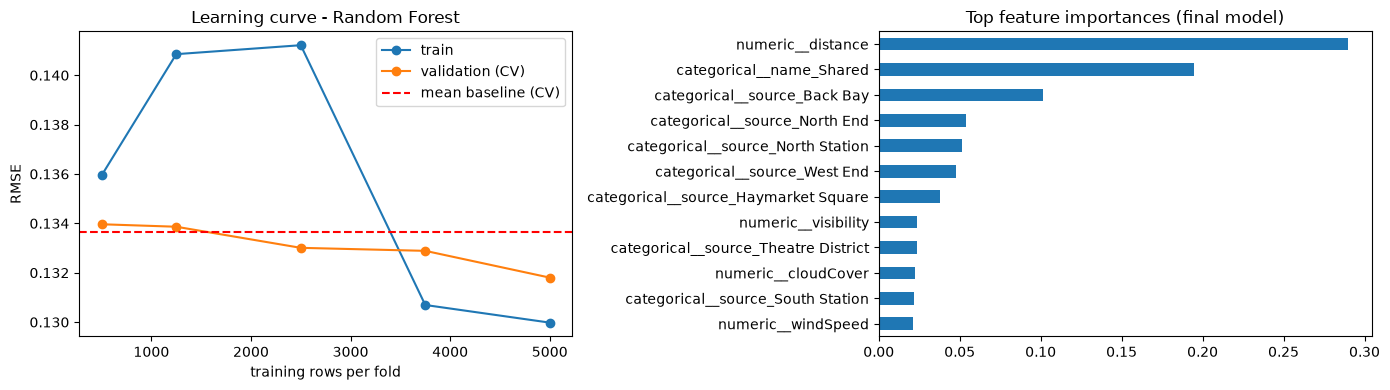

In [11]:
sizes, tr_scores, va_scores = learning_curve(tuned_pipeline(FINAL), X_cv, y_cv, cv=cv,
                                             train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
                                             scoring="neg_root_mean_squared_error", n_jobs=-1)
lc = pd.DataFrame({"train rows": sizes, "train RMSE": -tr_scores.mean(1), "validation RMSE": -va_scores.mean(1),
                   "validation RMSE std": va_scores.std(1)})
display(lc.round(5))
base_rmse = pd.read_csv("reports/model_comparison.csv").set_index("Model").loc["Baseline (predict mean)", "Mean RMSE"]

model = joblib.load("models/best_model.joblib")
est = model.named_steps["model"]
imp = pd.Series(getattr(est, "feature_importances_", np.zeros(1)),
                index=model.named_steps["preprocessor"].get_feature_names_out()[:len(getattr(est, "feature_importances_", [0]))])
imp = imp.sort_values(ascending=False).head(12)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(lc["train rows"], lc["train RMSE"], "o-", label="train")
axes[0].plot(lc["train rows"], lc["validation RMSE"], "o-", label="validation (CV)")
axes[0].axhline(base_rmse, ls="--", color="red", label="mean baseline (CV)")
axes[0].set_xlabel("training rows per fold"); axes[0].set_ylabel("RMSE"); axes[0].set_title(f"Learning curve - {FINAL}"); axes[0].legend()
imp[::-1].plot.barh(ax=axes[1]); axes[1].set_title("Top feature importances (final model)")
plt.tight_layout(); plt.savefig("reports/figures/06_learning_curve_importance.png", dpi=100); plt.show()

## 5b. Why R² is low — surge comes in episodes that the inputs cannot explain
Rides are sorted by time. For every ride we look at whether the **previous** ride (same pickup area; and same area + same product) surged. Then we check how much the surge rate changes with the only inputs available at request time (hour, weekday).
Caveat: rides of the same area and minute come from the same API snapshot, so part of the persistence is a data-collection effect.

In [4]:
raw = pd.read_csv("data/processed/uber_cleaned.csv", usecols=["pickup_datetime", "source", "name", "surge_multiplier"],
                  parse_dates=["pickup_datetime"])
raw = raw.sort_values(["pickup_datetime", "source", "name"], kind="stable").reset_index(drop=True)
raw["surged"] = (raw["surge_multiplier"] > 1).astype(int)

rows = []
for label, keys in [("previous ride, same pickup area", ["source"]),
                    ("previous ride, same pickup area and product", ["source", "name"])]:
    prev = raw.groupby(keys)["surged"].shift(1)
    ok = prev.notna()
    rate = raw.loc[ok].groupby(prev[ok])["surged"].mean()
    rows.append({"Condition": label, "P(surge | previous did not surge)": rate[0.0], "P(surge | previous surged)": rate[1.0]})
persistence = pd.DataFrame(rows)
display((persistence.set_index("Condition") * 100).round(1).add_suffix(" (%)"))
persistence.round(4).to_csv("reports/surge_persistence.csv", index=False)

by_hour = raw.groupby(raw["pickup_datetime"].dt.hour)["surged"].mean() * 100
by_day = raw.groupby(raw["pickup_datetime"].dt.dayofweek)["surged"].mean() * 100
print(f"Overall surge rate: {raw['surged'].mean() * 100:.1f}%")
print(f"Surge rate by hour of day:  min {by_hour.min():.1f}%  max {by_hour.max():.1f}%")
print(f"Surge rate by day of week:  min {by_day.min():.1f}%  max {by_day.max():.1f}%")

,P(surge | previous did not surge) (%),P(surge | previous surged) (%)
Condition,,
"previous ride, same pickup area",4.1,44.5
"previous ride, same pickup area and product",6.6,9.7


Overall surge rate: 6.8%
Surge rate by hour of day:  min 5.9%  max 8.0%
Surge rate by day of week:  min 6.6%  max 6.9%


## 6. Missing values — the imputers inside the saved Pipeline
The real Lyft data has no missing features, so we inject missing values into a **copy** of 5 training rows
(the real data is not changed). Then we show that the saved Pipeline still predicts: the median and most-frequent
values it learned on the training set fill the gaps.

In [12]:
demo = X_train.head(5).copy()
demo.loc[demo.index[0], "distance"] = np.nan
demo.loc[demo.index[1], ["temperature", "humidity"]] = np.nan
demo.loc[demo.index[2], "short_summary"] = np.nan
demo.loc[demo.index[3], ["source", "windSpeed"]] = np.nan
print("Missing values injected:", int(demo.isnull().sum().sum()))
out = demo.assign(prediction_with_missing=model.predict(demo),
                  prediction_original=model.predict(X_train.head(5)))
display(out[["source", "short_summary", "distance", "temperature", "humidity", "windSpeed",
             "prediction_with_missing", "prediction_original"]])
num_imp = model.named_steps["preprocessor"].named_transformers_["numeric"].named_steps["imputer"]
print("Learned medians:", dict(zip(num_imp.feature_names_in_, num_imp.statistics_.round(3))))

Missing values injected: 6


,source,short_summary,distance,temperature,humidity,windSpeed,prediction_with_missing,prediction_original
0,Boston University,Foggy,NaN,41.83,0.92,0.51,1.046912,1.057874
1,North End,Foggy,1.23,NaN,NaN,0.51,1.000000,1.000000
2,Beacon Hill,NaN,2.30,41.83,0.92,0.51,1.041471,1.041471
3,NaN,Foggy,3.06,41.83,0.92,NaN,1.017455,1.057874
4,Theatre District,Foggy,2.22,41.83,0.92,0.51,1.000000,1.000000


Learned medians: {'distance': np.float64(2.15), 'hour': np.float64(12.0), 'day_of_week': np.float64(3.0), 'is_weekend': np.float64(0.0), 'temperature': np.float64(40.92), 'precipIntensity': np.float64(0.0), 'humidity': np.float64(0.72), 'windSpeed': np.float64(4.89), 'visibility': np.float64(9.891), 'cloudCover': np.float64(0.81)}


## 7. Tuning on a 30k sample — is it representative?
Fit time per fold on the 30k sample (from notebook 04) explains why the sample is needed: SVR is roughly O(n²),
and KNN / MLP are also slow on 245k rows × 5 folds × every grid point. To check that the sample does not bias the
choice, the **final model** (tuned parameters) is cross-validated on the **full** training set with the same
`TimeSeriesSplit(5)`, and compared with the CV result on the sample and the stored one-time test result
(read from `final_metrics.json`; the test set is not touched again).

In [13]:
display(pd.read_csv("reports/model_comparison.csv")[["Model", "Fit time (s)"]].sort_values("Fit time (s)", ascending=False).round(2))

t0 = time.time()
full = cross_validate(tuned_pipeline(FINAL, X=X_train), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=5)
print(f"Full-train CV took {time.time()-t0:.0f}s")
t = tuning.set_index("Model").loc[FINAL]
consistency = pd.DataFrame({
    "RMSE": [t["After RMSE"], -full["test_RMSE"].mean(), final_metrics["test"]["RMSE"]],
    "RMSE std": [t["After RMSE std"], full["test_RMSE"].std(), np.nan],
    "R2": [t["After R2"], full["test_R2"].mean(), final_metrics["test"]["R2"]],
    "Baseline RMSE": [base_rmse, np.nan, final_metrics["baseline_test"]["RMSE"]],
}, index=["CV on 30k training sample", "CV on full training set (245k)", "Test set (notebook 05, final evaluation)"])
display(consistency.round(5))
consistency.round(6).to_csv("reports/cv_vs_test_consistency.csv")

,Model,Fit time (s)
7,SVR,50.00
6,Random Forest,19.21
12,ANN (MLP),7.53
13,Polynomial Regression (deg 2),2.72
9,XGBoost (bonus),2.30
3,HistGradientBoosting (bonus),1.44
2,LightGBM (bonus),0.67
11,Decision Tree,0.47
1,Baseline (predict mean),0.28
10,Linear Regression (Gradient Descent),0.28


Full-train CV took 170s


,RMSE,RMSE std,R2,Baseline RMSE
CV on 30k training sample,0.13168,0.00659,0.02908,0.13366
CV on full training set (245k),0.13263,0.00257,0.03668,NaN
"Test set (notebook 05, final evaluation)",0.13524,NaN,0.04304,0.13825
